# 10 · 三维 DeepONet：连续空间与时间查询、自动微分残差

**前置：** 02、08；PyTorch 自动微分。**目标：** 用一个初值编码查询任意 $(x,y,z,t)$，并计算 $u_t-\nu\Delta u$，避免把时间固定在模型输出维度中。

周期三维热方程 $u_t=\nu\Delta u$，本章固定 $\nu=0.04$，时间范围 $[0,0.3]$。branch 接收 $6^3$ 个固定初值传感器；trunk 接收四个连续坐标。与 08 的“输出一个三维网格”不同，本章可查询不规则空间点及任意区间内时间。

采用带周期特征与时间因子的 DeepONet 教学变体：$u_\theta(u_0,q)=\sum_j b_j(u_0)s_j(x,y,z)\tau_j(t)$。空间特征使用与生成数据一致的有限波矢集合；这是明确的低频先验，适合说明连续查询，但不是任意频率、任意几何上的通用保证。

参考：[DeepONet](https://arxiv.org/abs/1910.03193)、[autograd.grad](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html)。

## 原理详解 A：解函数依赖四个坐标，算子输入仍是一个初值函数

本章定义
$$
\mathcal G(u_0)(x,y,z,t)=u(x,y,z,t),\qquad u_t=\nu\Delta u.
$$
branch 输入是固定 $6^3=216$ 个传感器值，trunk 输入是一个 $q=(x,y,z,t)$。四个查询坐标不表示有四个空间维度：前三个是空间，第四个是时间。

真实有限模式解为
$$
u(\boldsymbol x,t)=
\sum_r c_r(u_0)\phi_r(\boldsymbol x)e^{-\nu\lambda_rt}.
$$
每个空间模式都有自己的衰减率。因此“空间基 × 时间系数”是适合本章的分离结构。模型将它推广为
$$
u_\theta(u_0,q)=\sum_{j=1}^p
b_j(P_su_0)\,s_j(x,y,z)\,\tau_j(t).
$$
空间和时间部分都通过 latent 索引 j 相乘，再与 branch 特征做内积。时间函数由 Tanh 网络学习，没有把解析指数衰减写入它。

这里 branch 是无偏置线性层，因此对固定查询 q，预测严格满足输入叠加关系。这符合固定参数线性热方程的结构，而不是仅期待训练把叠加关系近似学出来。

## 原理详解 B：周期特征先验与可表达函数的范围

空间特征是预选波矢的 sin/cos：
$$
\Phi(\boldsymbol x)=
[\sin(2\pi\boldsymbol k_1\cdot\boldsymbol x),
\cos(2\pi\boldsymbol k_1\cdot\boldsymbol x),\ldots].
$$
本章 $s_j(\boldsymbol x)$ 是这些特征的线性组合，因此模型任意时刻的输出始终位于同一个有限空间频带。这保证空间周期性，并让密网格查询可由解析特征表达，不需要从输出网格插值。

代价是模型无法表示该特征集合之外的新空间模式。当前集合也不含零模，所以不能表示任意非零均值初值的响应；训练初值恰好均值为零。若要学习一般初值，应补常数空间特征，并在数据中加入非零均值样本。

传感器值到 mode 系数的转换由 branch 学习，而不是把生成数据时的 Fourier 系数偷偷作为输入。规则 6³ 传感器足以分辨当前低频函数族，但改变输入频带后仍可能发生混叠。

latent 维度 p 是分离项数量，空间特征数是另一个容量限制。把 p 从 32 提高到 128，不会自动增加新的空间频率，因为 s 仍由同一组 16 个 sin/cos 特征张成。

因此密空间查询的成功部分来自显式频带先验。它是一个可解释的教学设计，不应被描述成仅靠网络容量实现的通用超分辨率。

## 原理详解 C：为什么 paired 查询适合求坐标导数？

forward 用 $[B,p]@[p,Q]$ 得到所有函数与查询的笛卡尔积。paired 则让第 i 条输入函数仅在第 i 个坐标查询：
$$
u_i=u_\theta(s_i,q_i).
$$
若样本之间不相互混合，则
$$
\frac{\partial\sum_i u_i}{\partial q_j}
=\frac{\partial u_j}{\partial q_j}.
$$
所以对输出和调用 autograd.grad 能得到每行自己的梯度。若直接对 forward 的 $B\times Q$ 输出求和，某个 q 的梯度会把 B 条不同函数的导数加在一起，不是其中某条函数的 PDE 残差。

本网络无跨查询 attention 或批次统计耦合，符合上述独立条件。对其他会混合查询的网络，需要分析完整 Jacobian，不能直接照搬求和技巧。

一阶梯度为 $g=(u_x,u_y,u_z,u_t)$；再对 $g_x,g_y,g_z$ 分别求导，取对应对角项：
$$
\Delta u=u_{xx}+u_{yy}+u_{zz},\qquad
r=u_t-\nu\Delta u.
$$
代码每次对某个梯度分量的和求导，再选同一坐标轴，取得 Hessian 对角元素，而不是把所有二阶偏导或混合项加在一起。

时间输入在网络中除以 0.3，autograd 对物理 t 求导时会自动包含链式因子 $1/0.3$。若手工对归一化时间求导，则必须自己恢复这个尺度。

一阶导数要 create_graph=True，才能继续求二阶导。若还要让 PDE 残差训练网络参数，二阶导也要保留求导图。单纯诊断不需要保存完整二阶参数图，可减少内存。见 [autograd.grad 文档](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html)。

## 原理详解 D：查询分布、初值监督与导数误差

训练查询中，192 点随机分布于时空区域，64 点固定为 t=0，因此当前目标是“随机时空误差 + 额外初值监督”的混合，不是严格均匀的四维积分损失。初值点占 1/4 的查询权重；如果改变它们数量，就改变了目标的相对权重。

初值监督不是硬初值约束。训练后 t=0 仍可能有误差；仅加入更多 t=0 数据也不等于结构上严格满足初值。可进一步设计 $u_\theta=u_0+t\,w_\theta$，但任意坐标上的 u0 需要可靠的函数重建，不能凭空从稀疏传感器读取。

损失只约束函数值时，学到的时间因子可以在查询点上接近参考值，而导数不够准确。对某个潜在模式，PDE 还要求对应的时间变化与空间 Laplace 一致：
$$
\tau'(t)+\nu\lambda\tau(t)=0.
$$
值接近不保证这个 ODE 关系也接近，故本章单独报告自动微分残差。

解析解残差检查只验证“求导程序与公式正确”；模型残差诊断评估的是另一个对象。两者必须分开，不能因为解析残差接近零就说模型满足了 PDE。

最后分别报告 t=0、区间内多个时刻和随机时空点。整体平均可能隐藏末端时间的误差，按时间分层诊断能判断模型究竟在哪些条件下可靠。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic("matplotlib", "inline")
from tutorial_utils import *
from tutorial_3d_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


## 1. 传感器、训练查询和函数级划分

训练、验证、测试初值函数分别采样。训练用一组随机时空查询，另加 $t=0$ 点用于初值监督。验证查询独立，测试使用从未参加训练的规则体积网格与时间。数据按函数划分，不能把同一函数的不同坐标拆成训练和测试来宣称新函数泛化。

参考解由已知 Fourier 系数解析计算；这些系数仅供数据生成和评估，不作为模型输入。

In [2]:
ntrain,ntest = (16,4) if SMOKE else (96,16)
atrain = torch.randn(ntrain,NCOEFF)
aval,atest = torch.randn(ntest,NCOEFF),torch.randn(ntest,NCOEFF)
sensor_train,sensor_val,sensor_test = [
    field3d(a,6).flatten(1) for a in [atrain,aval,atest]]
def random_queries(count):
    q = torch.rand(count,4)
    q[:,3] *= 0.3
    return q
qtrain = random_queries(48 if SMOKE else 192)
qinitial = random_queries(16 if SMOKE else 64); qinitial[:,3] = 0
qtrain = torch.cat([qtrain,qinitial])
qval = random_queries(64 if SMOKE else 256)
ytrain = heat_at_queries(atrain,qtrain)
yval = heat_at_queries(aval,qval)
print("sensors:",sensor_train.shape,"queries:",qtrain.shape,
      "targets:",ytrain.shape)

sensors: torch.Size([96, 216]) queries: torch.Size([256, 4]) targets: torch.Size([96, 256])


## 2. 一个 branch 编码，多个 trunk 查询

branch 是线性编码，因为本章固定参数的热方程解算子本身线性。trunk 的空间编码也是线性地组合周期特征，但时间因子由 Tanh 网络学习。时间衰减没有硬编码进网络。

`forward` 输出全部函数与全部查询的笛卡尔积 $[B,Q]$；`paired` 只输出一对一的函数—坐标配对，方便求坐标导数。周期特征保证空间周期性，而初始条件仅为监督约束。

epoch 1 MSE 2.070957084496816 validation L2 0.7515257000923157


epoch 40 MSE 0.008170360776906213 validation L2 0.07226830720901489


epoch 80 MSE 0.006276068976148963 validation L2 0.060480471700429916


epoch 120 MSE 0.007298560036967198 validation L2 0.06261231750249863


epoch 160 MSE 0.004855052606823544 validation L2 0.04781499132514


epoch 200 MSE 0.003924954682588577 validation L2 0.04470246657729149


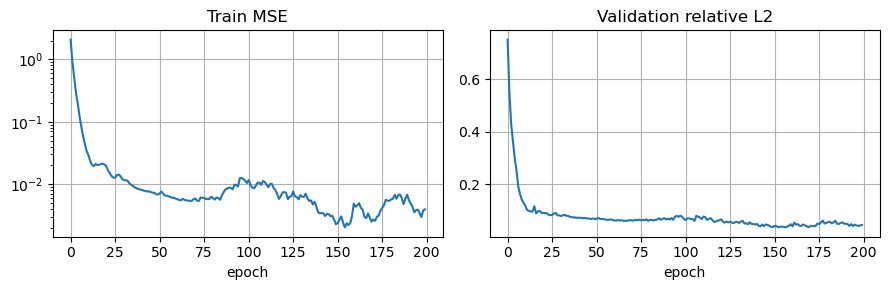

In [3]:
class SpaceTimeDeepONet(nn.Module):
    def __init__(self,nsensors=216,latent=32):
        super().__init__()
        self.branch = nn.Linear(nsensors,latent,bias=False)
        self.register_buffer("wavevectors",torch.tensor(WAVEVECTORS,dtype=torch.float32))
        self.spatial = nn.Linear(NCOEFF,latent,bias=False)
        self.temporal = nn.Sequential(nn.Linear(1,64),nn.Tanh(),
                                      nn.Linear(64,64),nn.Tanh(),nn.Linear(64,latent))
    def trunk(self,q):
        angles = 2*torch.pi*(q[:,:3]@self.wavevectors.T)
        spatial = torch.stack([angles.sin(),angles.cos()],dim=-1).flatten(1,2)
        return self.spatial(spatial)*self.temporal(q[:,3:4]/0.3)
    def forward(self,sensors,q):
        return self.branch(sensors)@self.trunk(q).T
    def paired(self,sensors,q):
        if len(sensors)!=len(q): raise ValueError("paired requires one function per query")
        return (self.branch(sensors)*self.trunk(q)).sum(-1)

model = SpaceTimeDeepONet()
# Training and validation use different query sets through a custom predict closure.
model.to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(),lr=0.002)
loader = DataLoader(TensorDataset(sensor_train,ytrain),batch_size=16,shuffle=True)
history = []
for epoch in range(epochs(200)):
    model.train(); total = 0.
    for sensors,target in loader:
        sensors,target = sensors.to(DEVICE),target.to(DEVICE)
        optimizer.zero_grad()
        prediction = model(sensors,qtrain.to(DEVICE))
        loss = (prediction-target).square().mean()
        if not torch.isfinite(loss): raise FloatingPointError("Non-finite loss")
        loss.backward(); optimizer.step(); total += loss.item()*len(sensors)
    model.eval()
    with torch.no_grad():
        vp = model(sensor_val.to(DEVICE),qval.to(DEVICE))
        val_error = relative_l2(vp,yval.to(DEVICE)).mean().item()
    history.append((total/ntrain,val_error))
    if epoch==0 or (epoch+1)%max(1,epochs(200)//5)==0:
        print("epoch",epoch+1,"MSE",history[-1][0],"validation L2",val_error)
history = np.asarray(history)
plot_history(history)

## 3. 同一组测试函数，在新空间网格与新时间上预测

输出网格 $12^3$ 比传感器 $6^3$ 更密，输入传感器布局不变。每个时间单独计算整个体积的相对误差。$t=0$ 是初值检查，其余时间是连续查询实验。

Test relative L2: mean=0.0404, median=0.0361, max=0.0546
query time: 0.0 volume relative L2: 0.04040161147713661
Test relative L2: mean=0.0406, median=0.0352, max=0.0591
query time: 0.07 volume relative L2: 0.04059825465083122
Test relative L2: mean=0.0439, median=0.0394, max=0.0658
query time: 0.19 volume relative L2: 0.043896276503801346
Test relative L2: mean=0.0699, median=0.0705, max=0.1006
query time: 0.3 volume relative L2: 0.06992857903242111


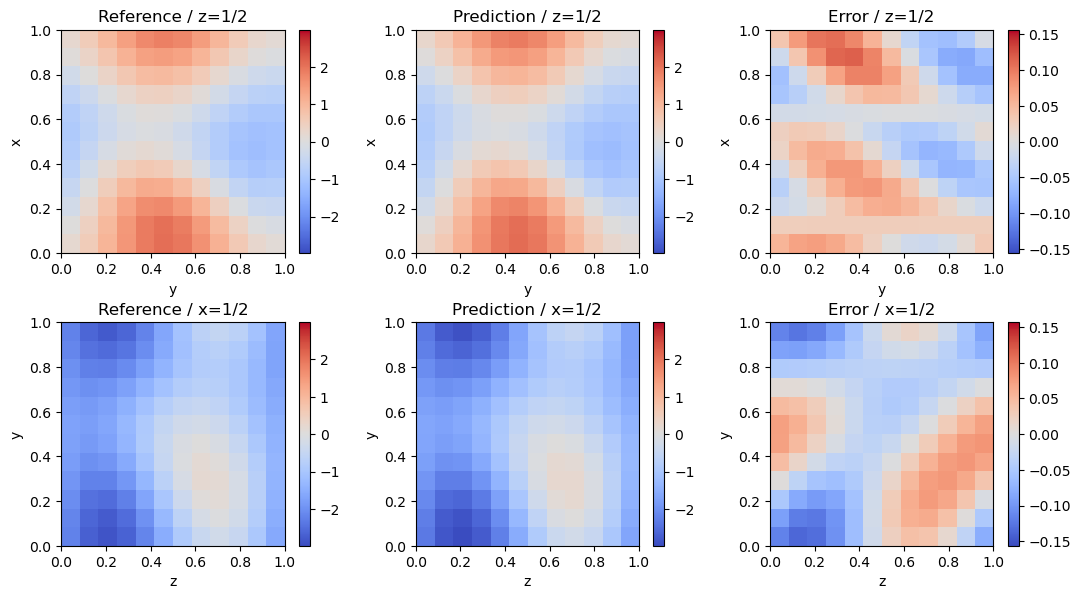

In [4]:
NQUERY = 8 if SMOKE else 12
xyz = periodic_grid3d(NQUERY).reshape(3,-1).T
volume_predictions = {}
for time in [0.,0.07,0.19,0.30]:
    q = torch.cat([xyz,torch.full((len(xyz),1),time)],dim=1)
    truth = heat_at_queries(atest,q)
    pred,error = report(model,sensor_test,truth,
        predict=lambda m,sensors: m(sensors,q.to(sensors.device)))
    volume_predictions[time] = (truth,pred)
    print("query time:",time,"volume relative L2:",error.mean().item())
truth,pred = volume_predictions[0.19]
show_volume_slices(truth.reshape(ntest,NQUERY,NQUERY,NQUERY),
                   pred.reshape(ntest,NQUERY,NQUERY,NQUERY))

## 4. 自动微分检查连续 PDE

一对一查询中，每个输出仅依赖对应的一行 q。对输出和求 `autograd.grad` 才能得到每行自己的导数；如果输出在不同查询之间混合，简单求和梯度就不能这样解释。

先对解析解验证导数程序，再评估模型。该残差是训练后诊断，**没有**加入本章训练损失。如果扩展为 PI-DeepONet，二阶导数也必须 `create_graph=True`，否则其对网络参数的反向图不完整。

In [5]:
def heat_residual_at_points(predict_fn,q,nu=0.04,for_training=False):
    q = q.detach().clone().requires_grad_(True)
    value = predict_fn(q)
    gradient = torch.autograd.grad(value.sum(),q,create_graph=True)[0]
    laplacian = torch.zeros_like(value)
    for axis in range(3):
        second = torch.autograd.grad(gradient[:,axis].sum(),q,
                                    create_graph=for_training,retain_graph=True)[0][:,axis]
        laplacian = laplacian+second
    return gradient[:,3]-nu*laplacian

qcheck = random_queries(24).double()
exact_fn = lambda q: heat_at_queries(atest[:1].double(),q).squeeze(0)
exact_residual = heat_residual_at_points(exact_fn,qcheck)
assert exact_residual.abs().max()<1e-9
print("Analytic derivative residual max:",exact_residual.abs().max().item())

model.eval()
qdiagnostic = random_queries(64).to(DEVICE)
# Keep gradients enabled: no torch.no_grad() around coordinate derivatives.
for index in range(min(2,ntest)):
    sensor = sensor_test[index:index+1].to(DEVICE)
    predict_fn = lambda q: model.paired(sensor.expand(len(q),-1),q)
    r = heat_residual_at_points(predict_fn,qdiagnostic)
    print("test function",index,"PDE residual RMS:",r.square().mean().sqrt().item())

Analytic derivative residual max: 1.7763568394002505e-15
test function 0 PDE residual RMS: 0.7484965920448303
test function 1 PDE residual RMS: 0.8805614113807678


## 5. 不规则点的函数泛化

下面仍使用完整独立测试函数，但输出坐标改为随机时空点。这里同时测试新输入函数与新查询位置。若想改变 branch 传感器数量，需要重新设计或训练 branch，而不是仅换 q。

Test relative L2: mean=0.0459, median=0.0458, max=0.0665


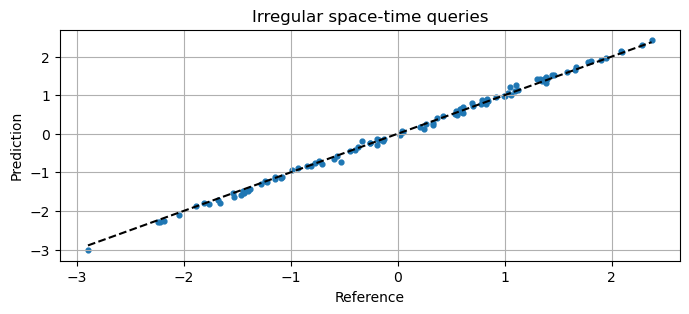

In [6]:
qrandom = random_queries(100)
random_truth = heat_at_queries(atest,qrandom)
random_pred,random_error = report(model,sensor_test,random_truth,
    predict=lambda m,sensors: m(sensors,qrandom.to(sensors.device)))
plt.scatter(random_truth[0].numpy(),random_pred[0].numpy(),s=12)
lo,hi = random_truth[0].min().item(),random_truth[0].max().item()
plt.plot([lo,hi],[lo,hi],"k--")
plt.xlabel("Reference"); plt.ylabel("Prediction")
plt.title("Irregular space-time queries"); plt.show()

**练习：** ① 给 branch 加入 $\nu$ 并改变数据分布，研究多参数解算子；② 加物理损失和初值损失，使用更多无标签初值函数；③ 将空间 Fourier 特征换成坐标 MLP，并比较周期边界和样本效率；④ 查询 $t>0.3$，将时间外推与区间内插值分开报告。

**自检：** 小解误差不必然意味着小 PDE 导数残差。连续坐标输入也不意味着模型已经学到所有空间频率。